# 3. Explainability of RS-FEDRAD with LIME and SHAP

We explain the RS-FEDRAD global model after ten FedAvg rounds (`models/rsfedrad_global_round10.h5`) on the held-out splits of the ten clients. The protocol follows XRan (Gulmez et al., 2024): LIME for local explanations of correctly and incorrectly classified samples, SHAP for location-based and feature-based global explanations. Because our sequences also carry ATT&CK techniques, we additionally measure how much of each decision the TTP features account for.

All outputs are produced by `python -m rsfedrad.explain` and stored in `results/explainability/`.

In [1]:
import os, sys, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from rsfedrad import config
XAI = config.XAI_DIR
import json

## 3.1 Predictions on the held-out data

In [2]:
summary = json.loads((XAI / "summary.json").read_text())
{k: v for k, v in summary.items() if k != "group_share_of_abs_shap"}

{'test_samples': 6030,
 'misclassified': 48,
 'false_positives': 24,
 'false_negatives': 24,
 'lime_cases': 8,
 'shap_samples': 400,
 'shap_completeness_correlation': 0.983}

## 3.2 Local explanations with LIME

For each explained sequence, LIME removes random subsets of the observed events (a removed position takes the value of an empty slot) and fits a weighted linear surrogate to the model's log-odds. A positive weight means the observed API call, DLL, mutex or technique pushes the decision towards ransomware. `local_r2` reports how well the surrogate reproduces the model around the sample.

In [3]:
lime = pd.read_csv(XAI / "lime_explanations.csv")
lime.groupby(["case", "kind", "label", "p_ransomware"]).local_r2.first().reset_index()

,case,kind,label,p_ransomware,local_r2
0,1,correct ransomware,Ransomware,1.0,0.853
1,2,correct ransomware,Ransomware,1.0,0.701
2,3,correct benign,Benign,0.0,0.463
3,4,correct benign,Benign,0.0,0.822
4,5,misclassified benign predicted as ransomware,Benign,1.0,0.410
5,6,misclassified benign predicted as ransomware,Benign,1.0,0.842
6,7,misclassified ransomware predicted as benign,Ransomware,0.0,0.903
7,8,misclassified ransomware predicted as benign,Ransomware,0.0,0.951


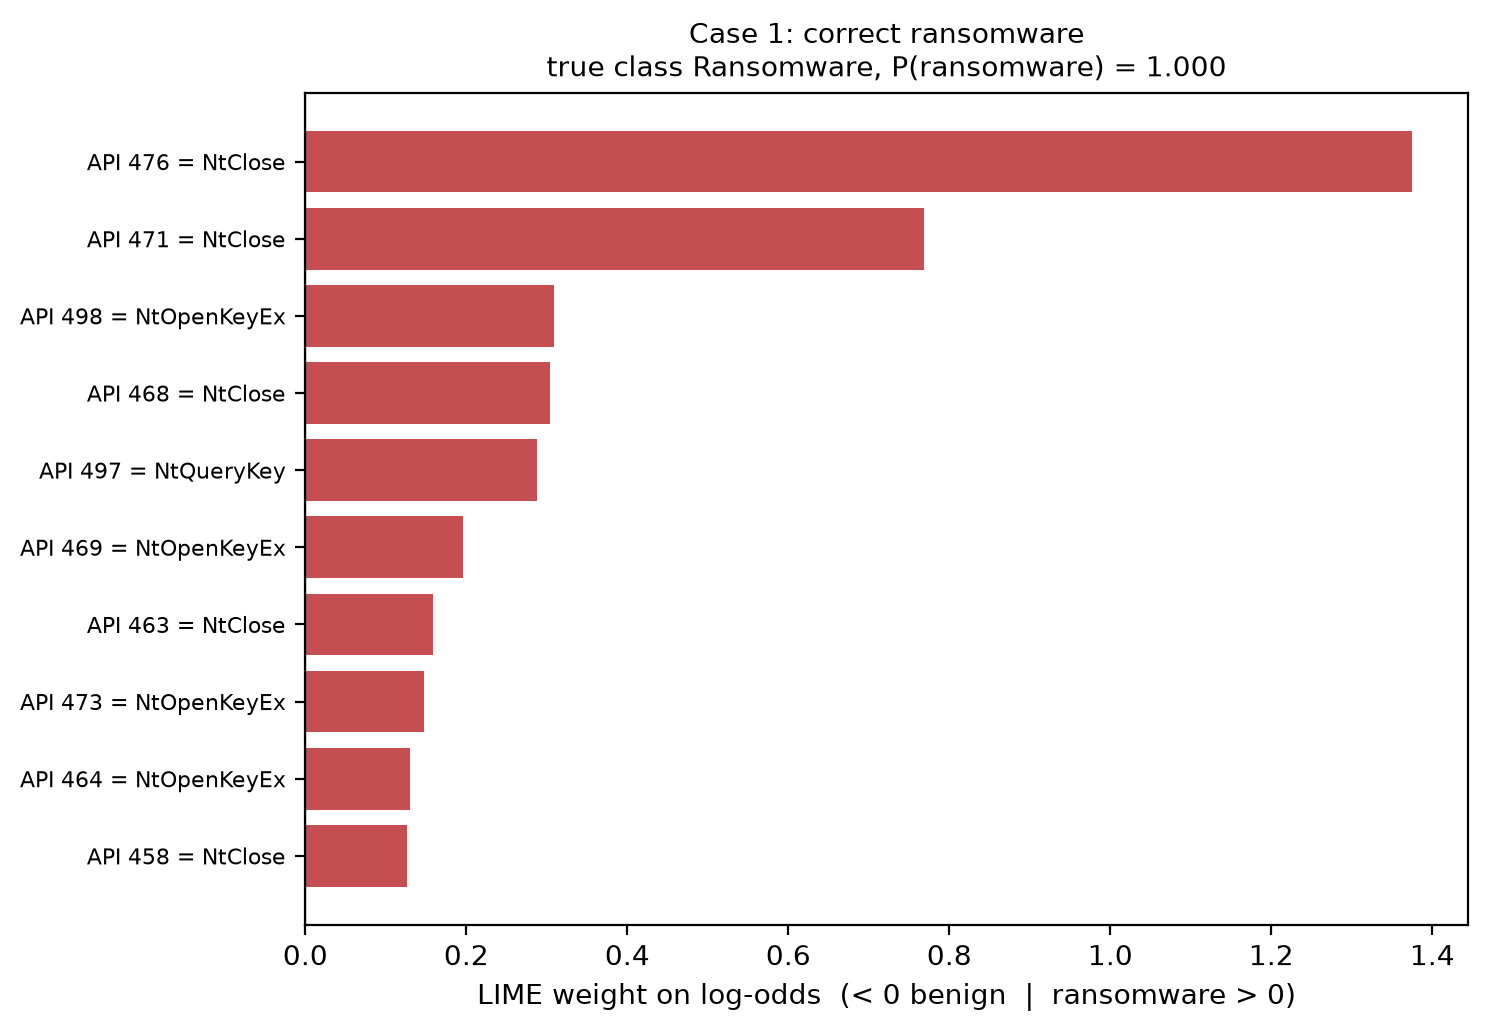

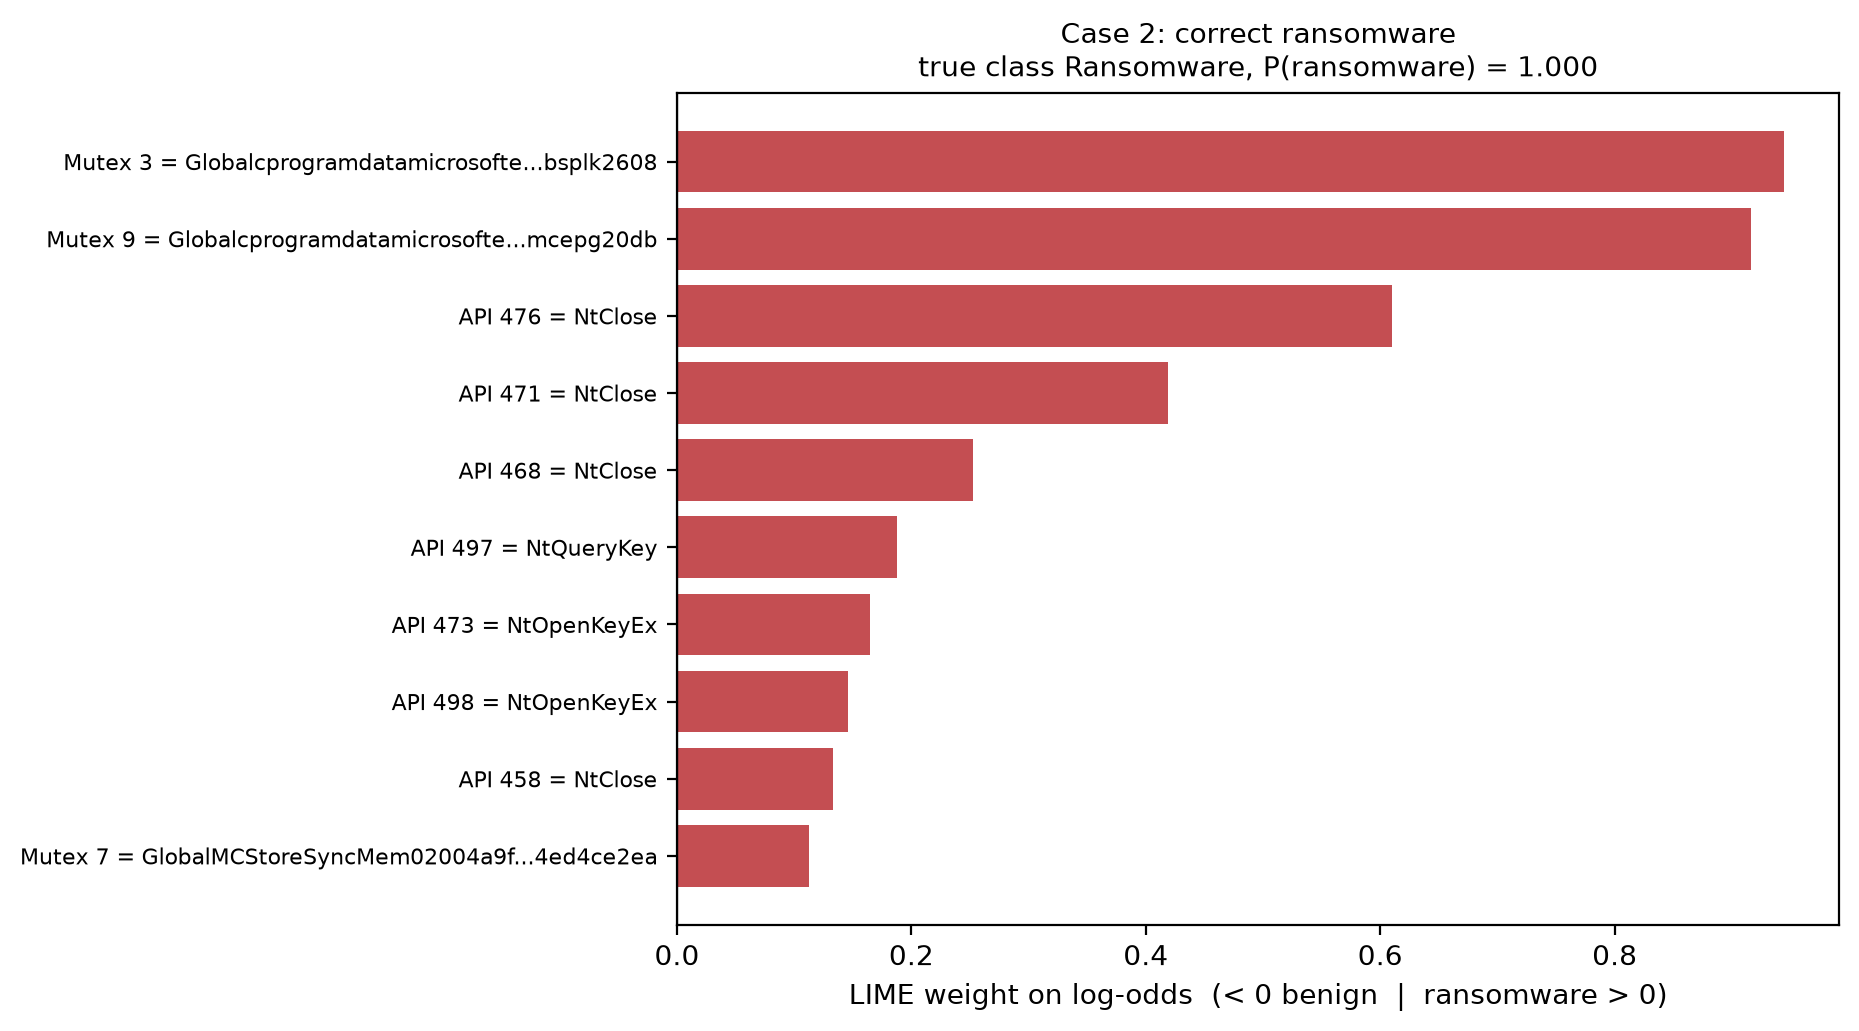

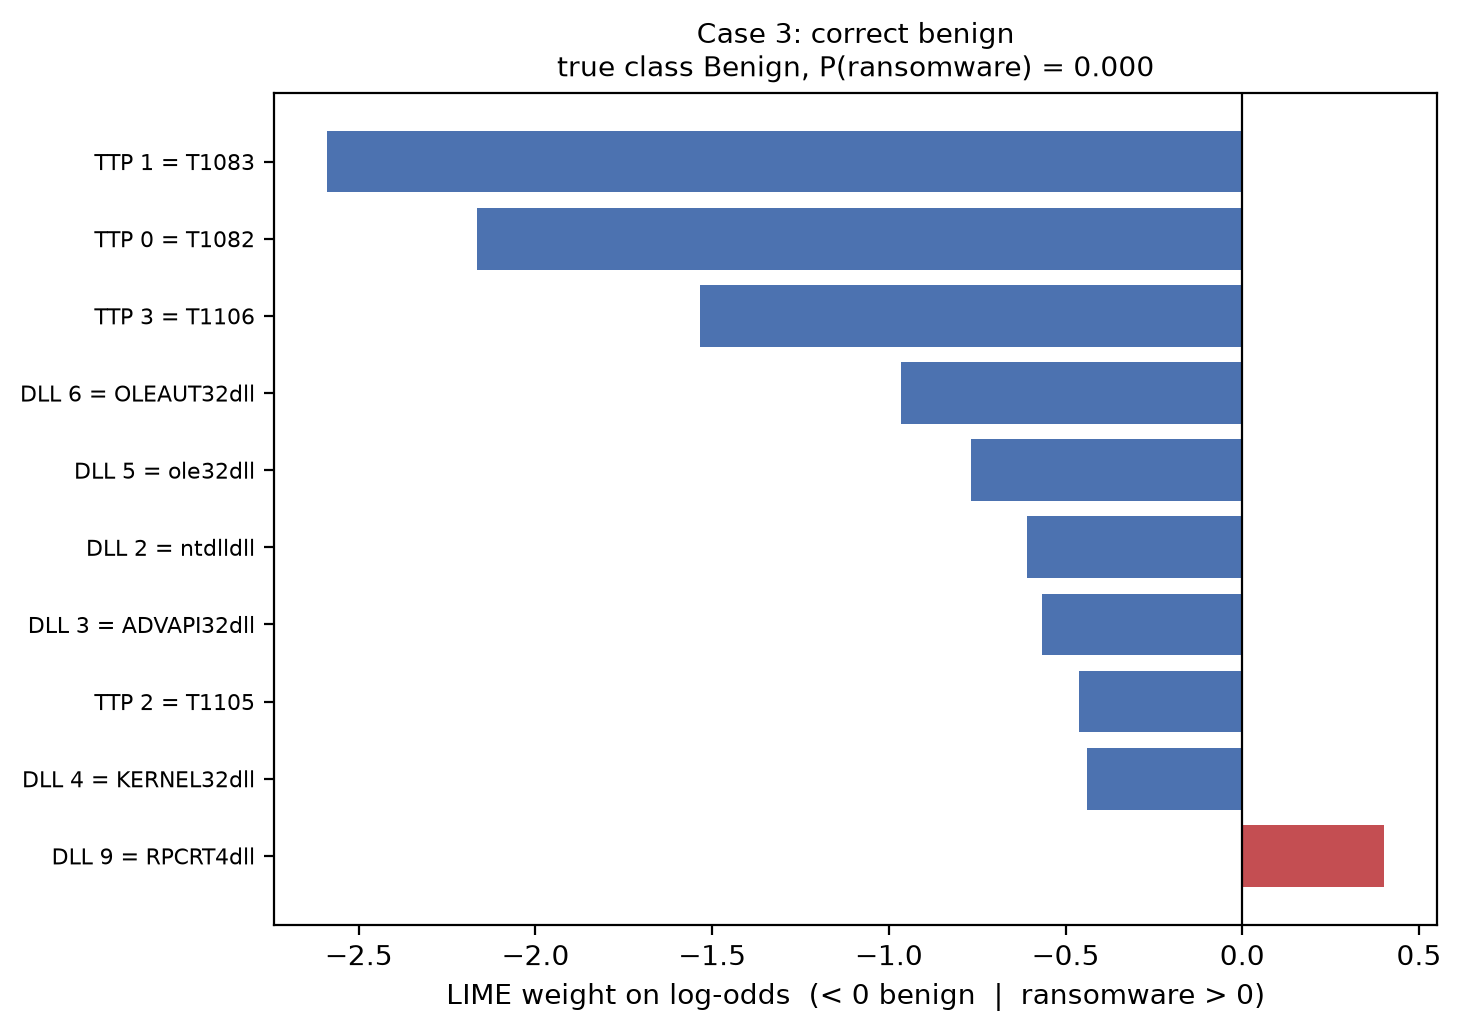

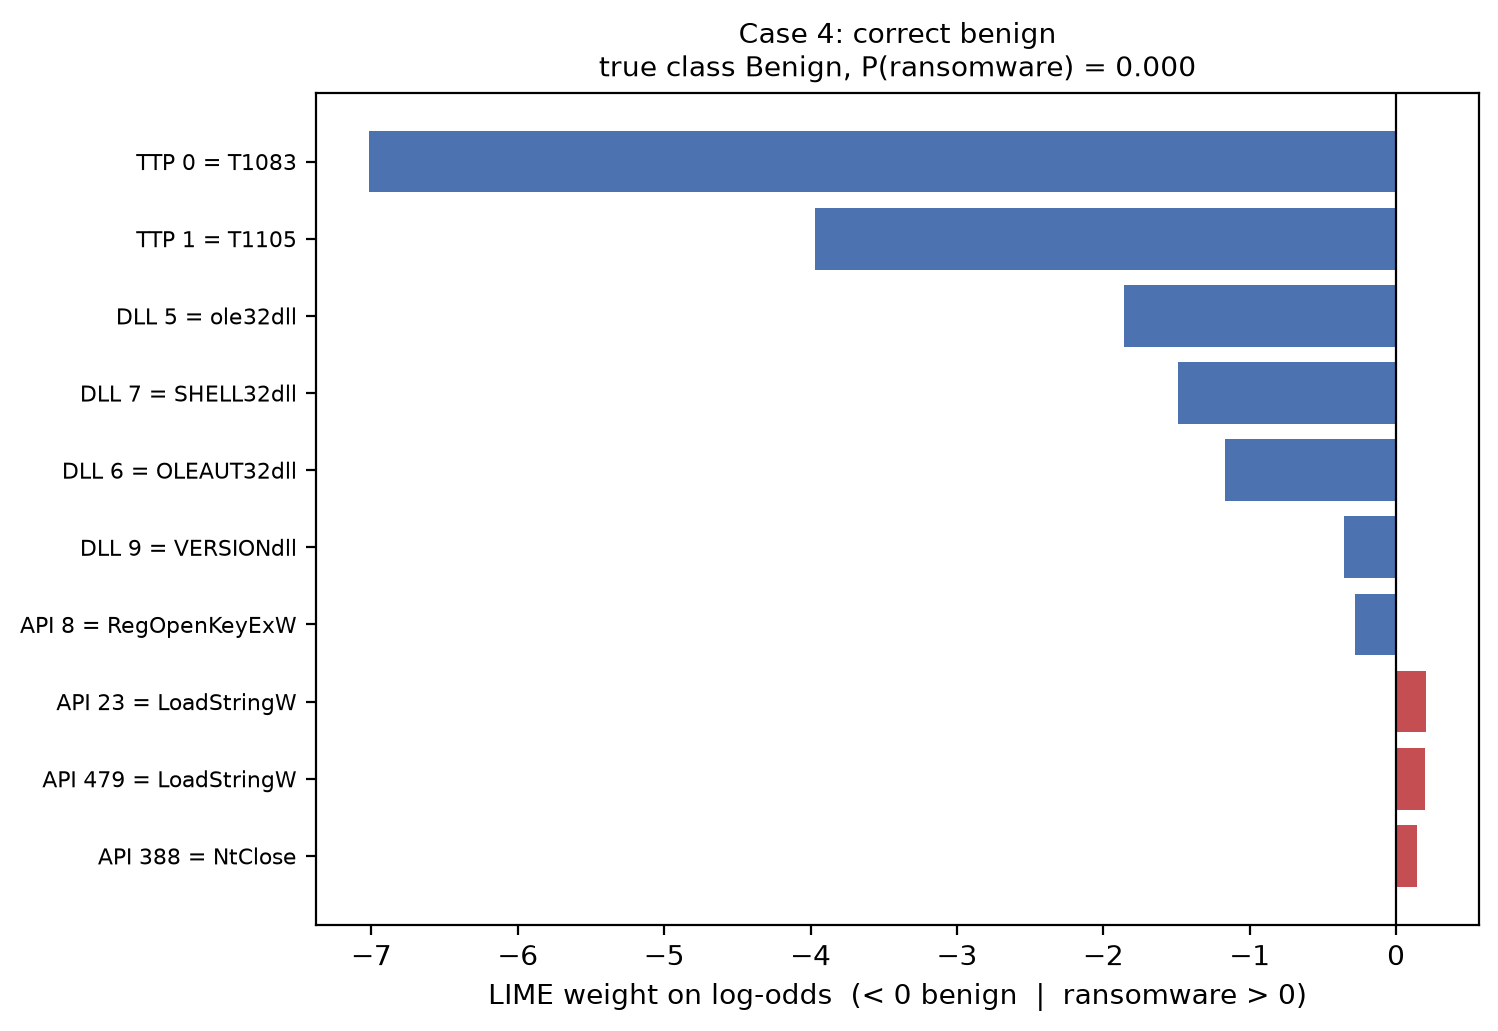

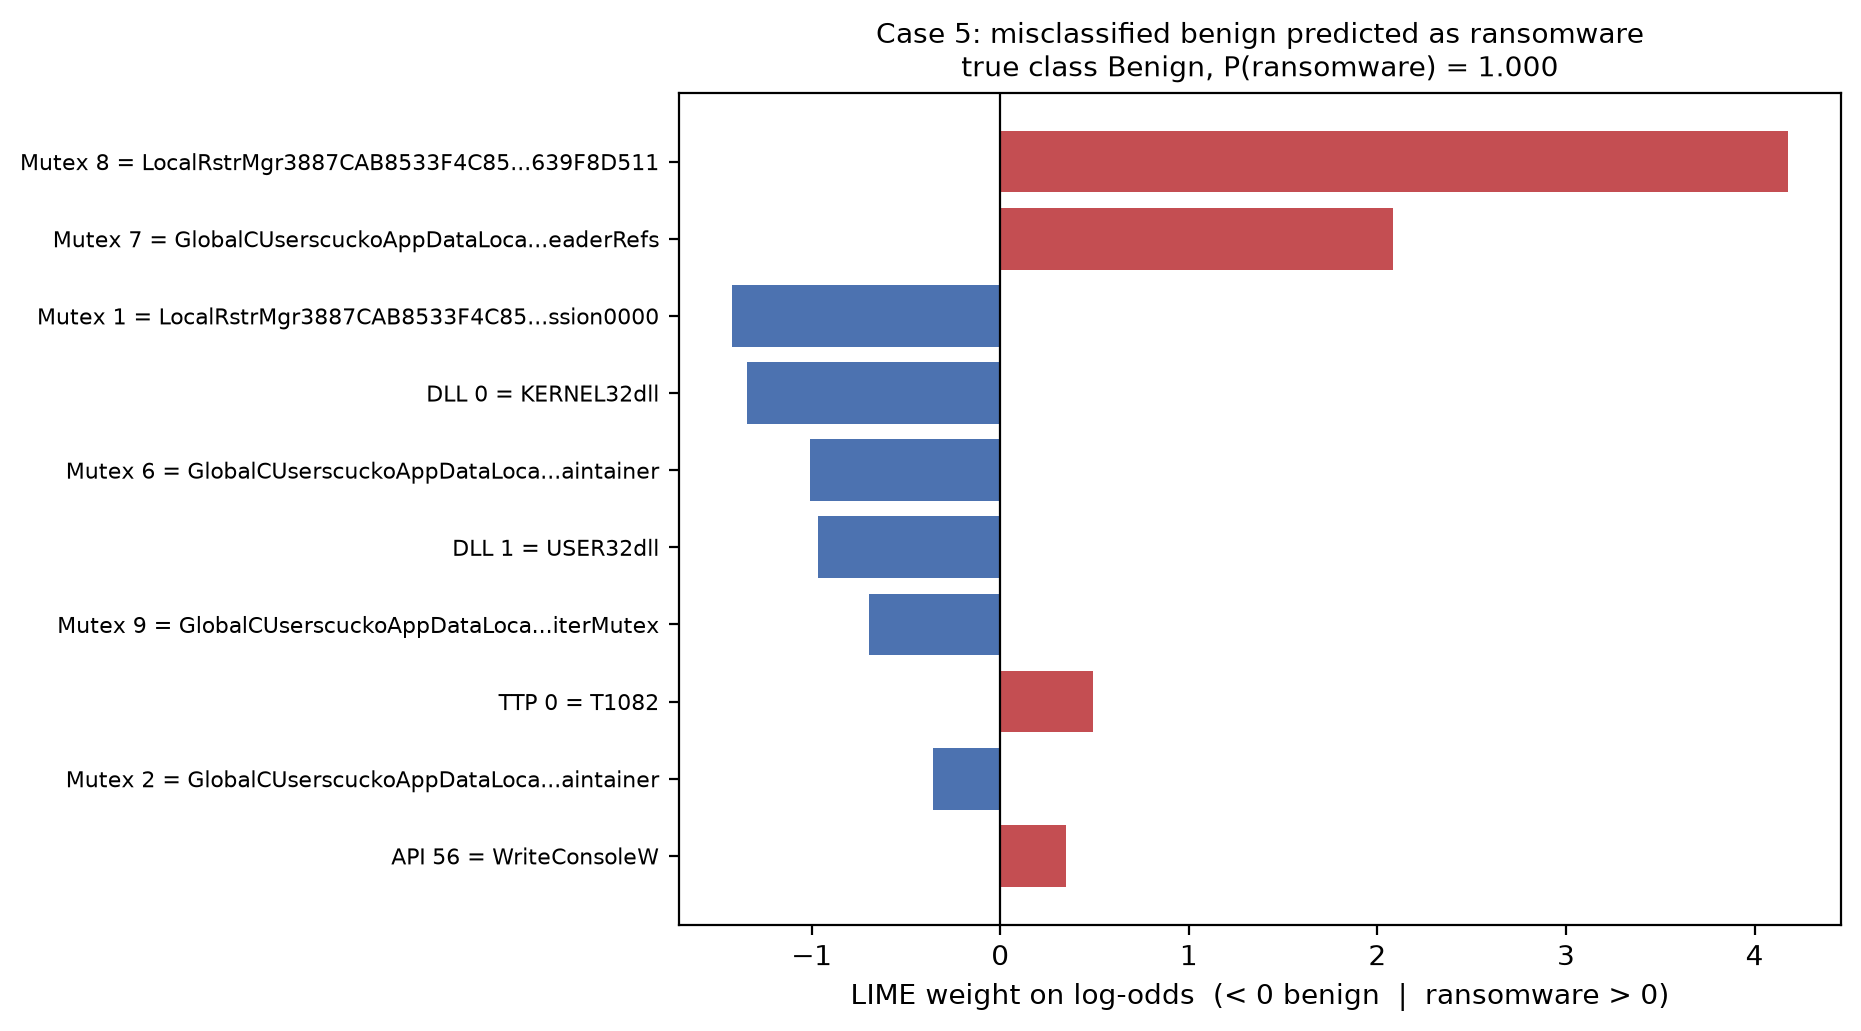

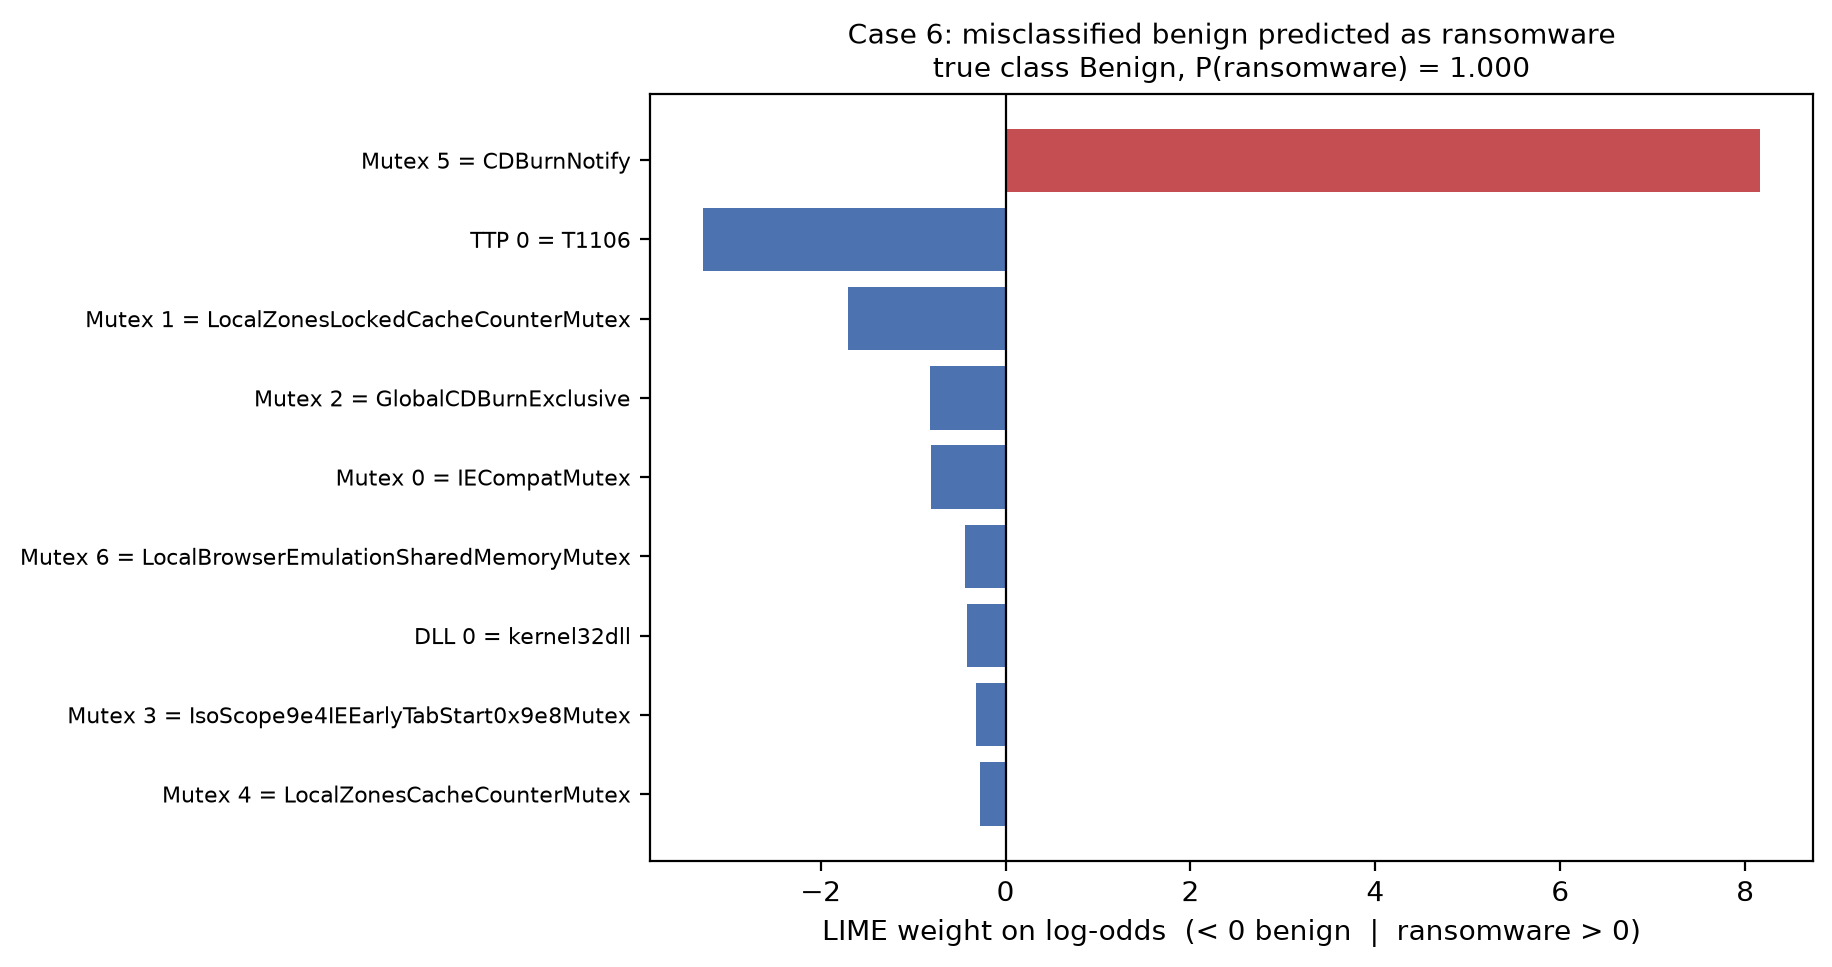

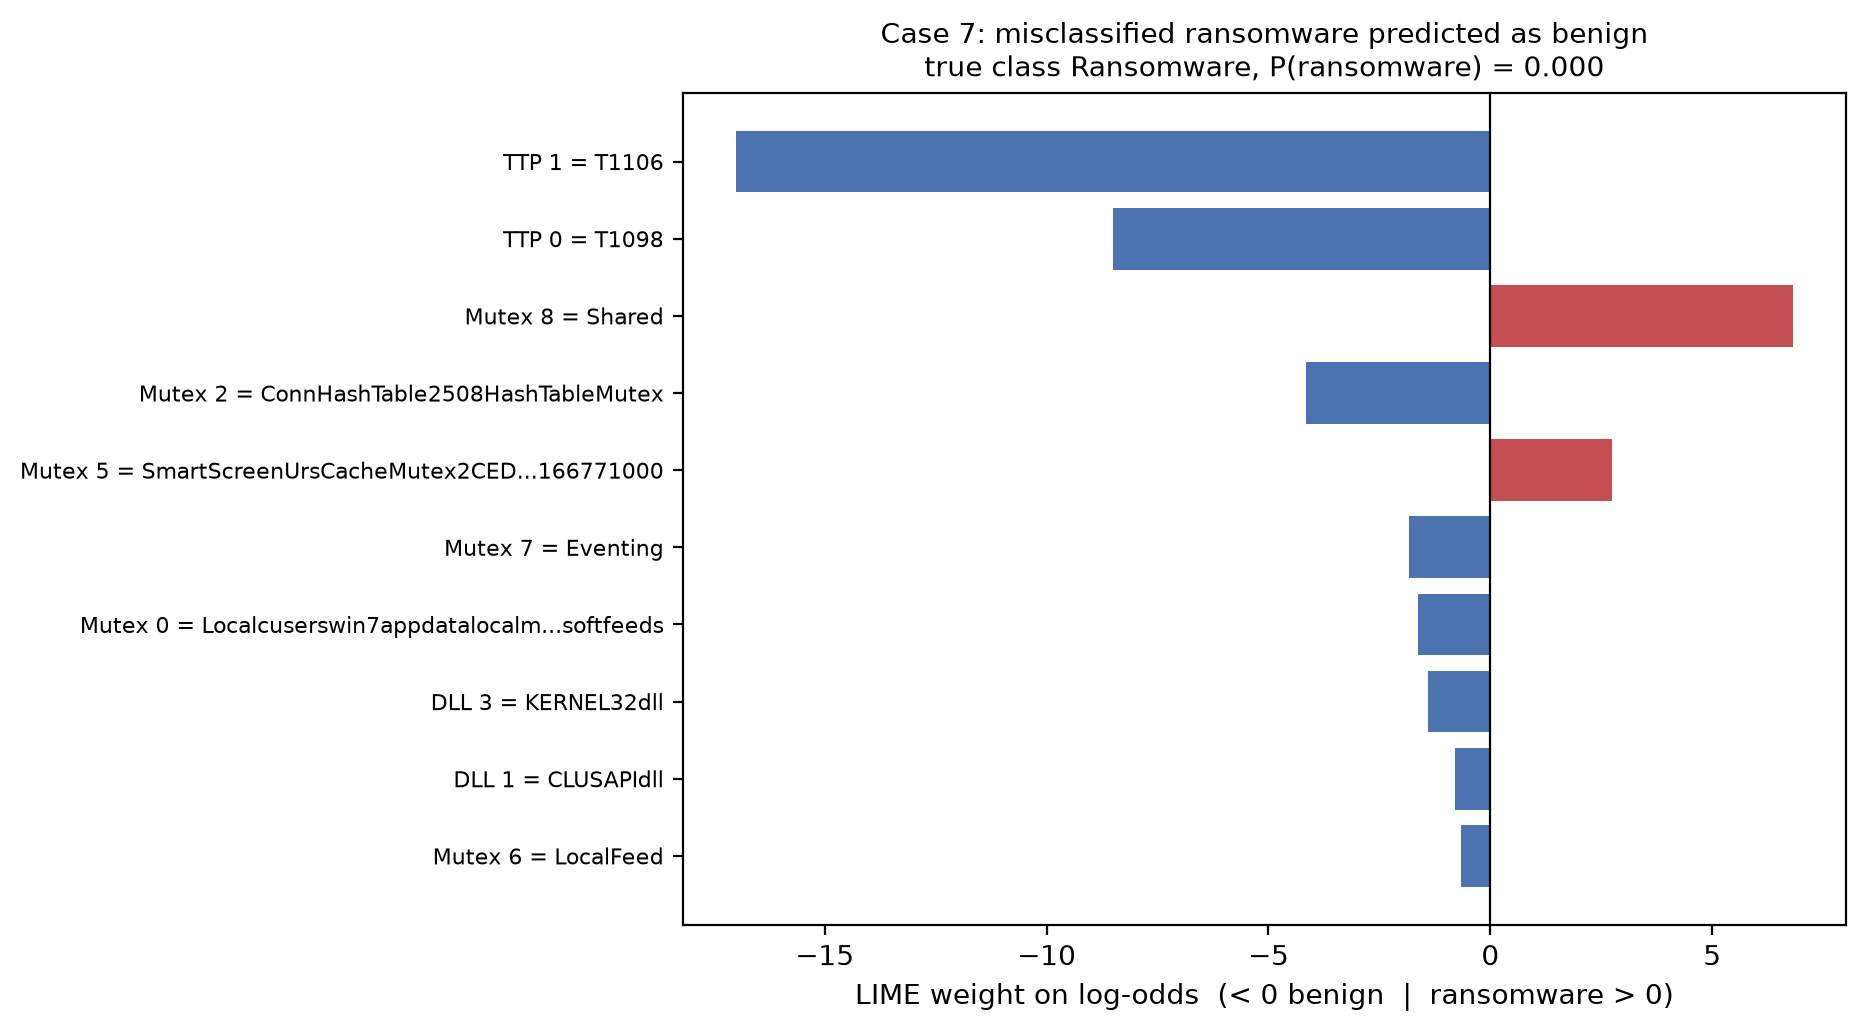

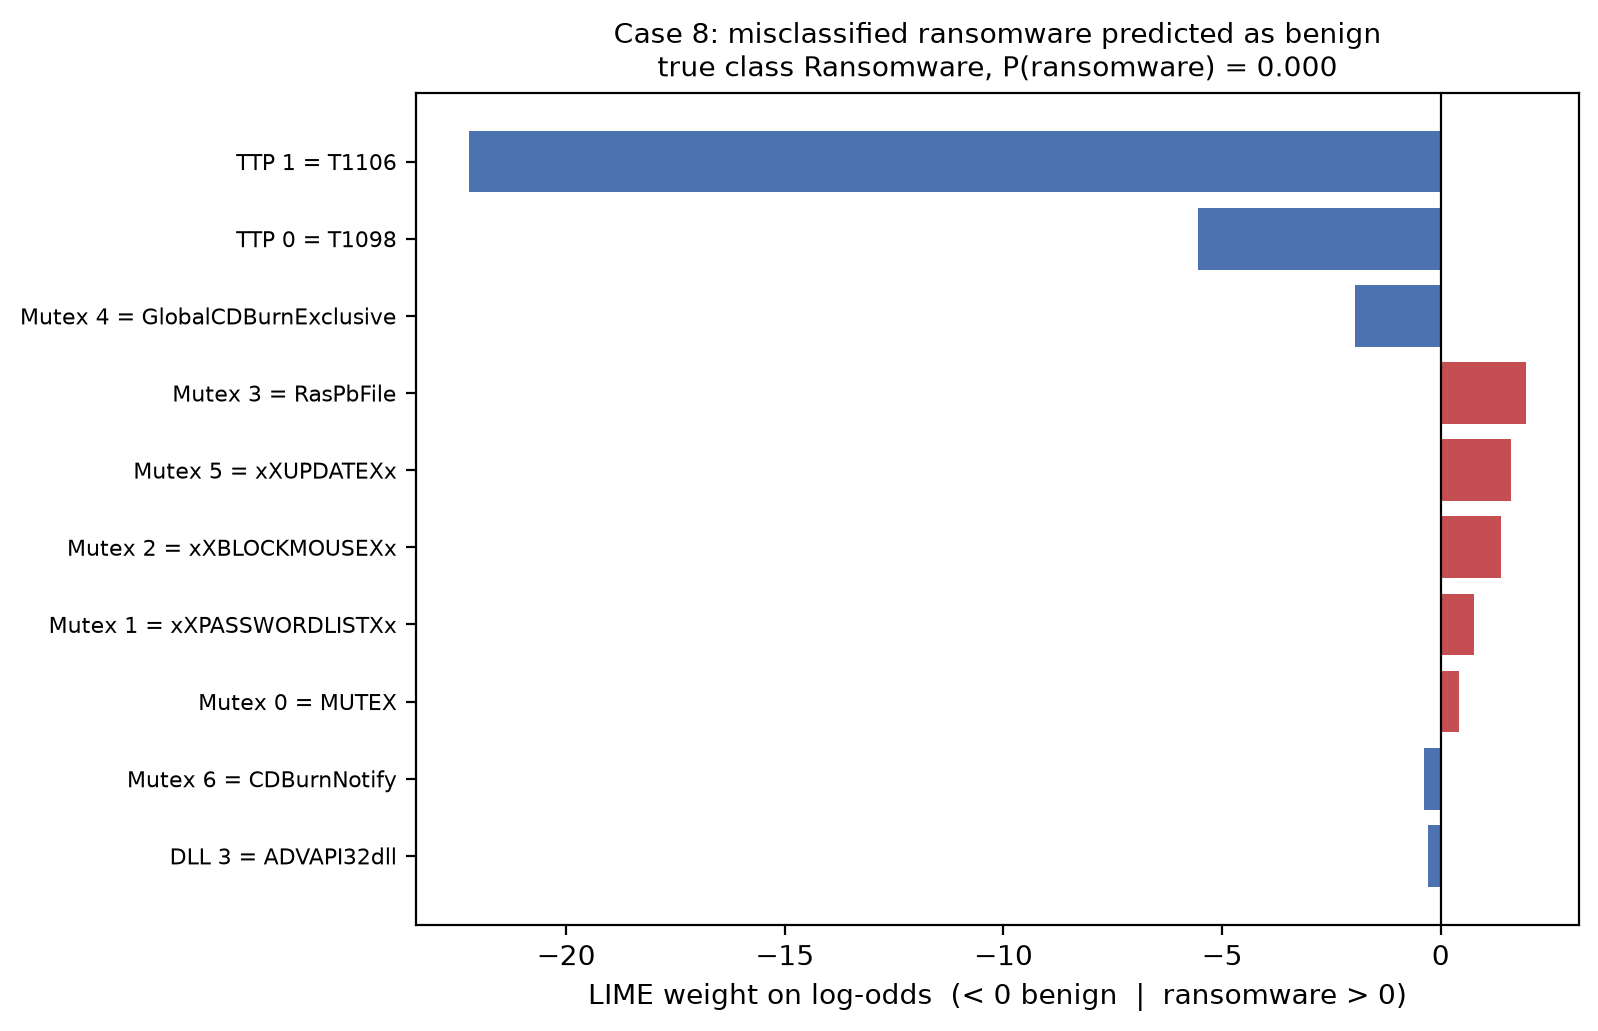

In [4]:
for case in sorted(lime.case.unique()):
    display(Image(str(XAI / f"lime_case_{case}.png"), width=560))

## 3.3 Location-based global explanation (SHAP)

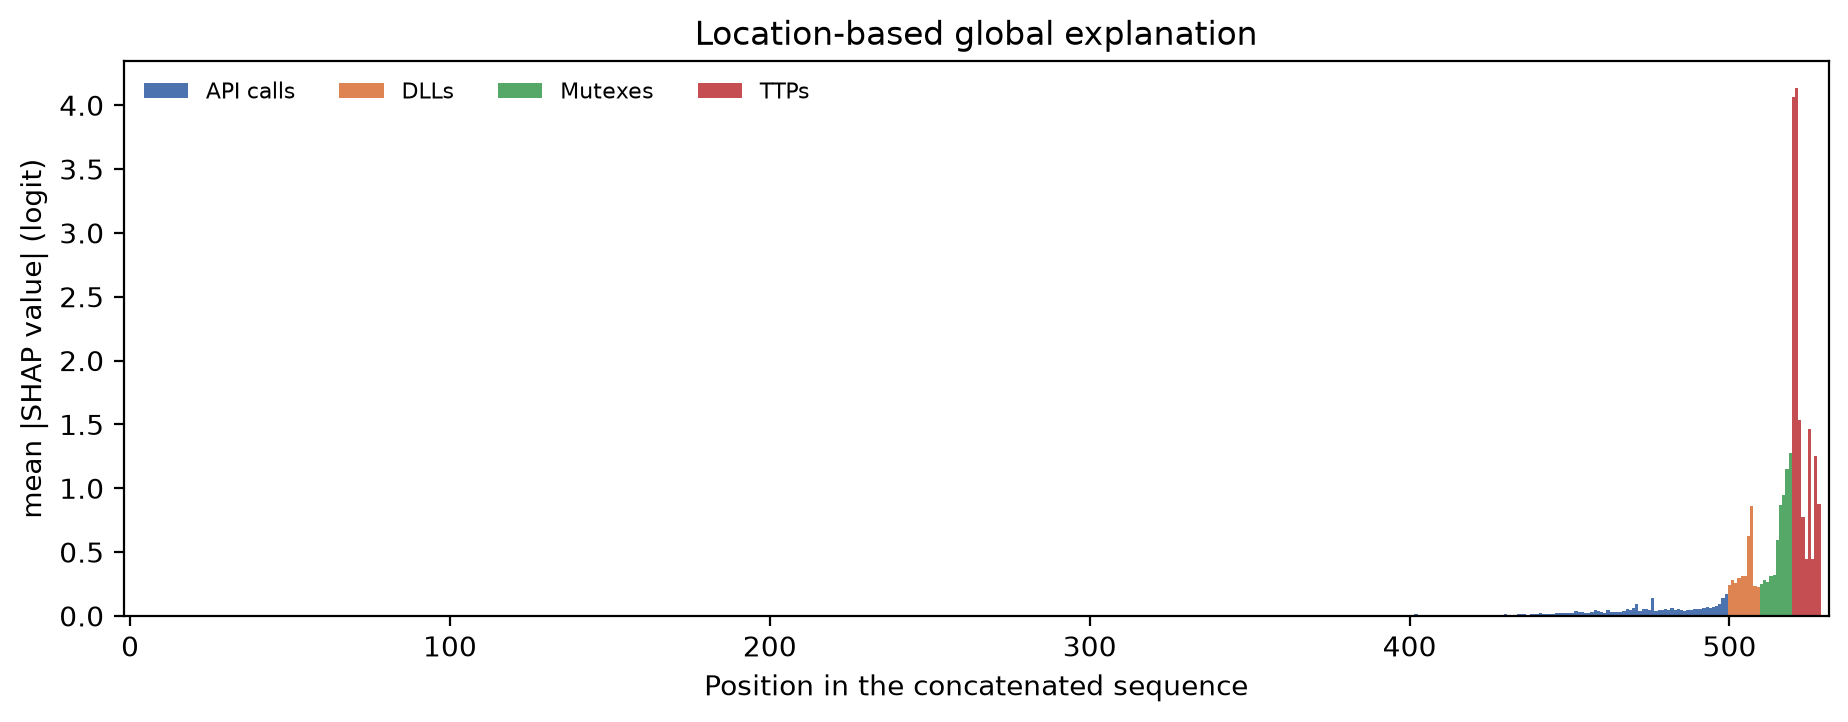

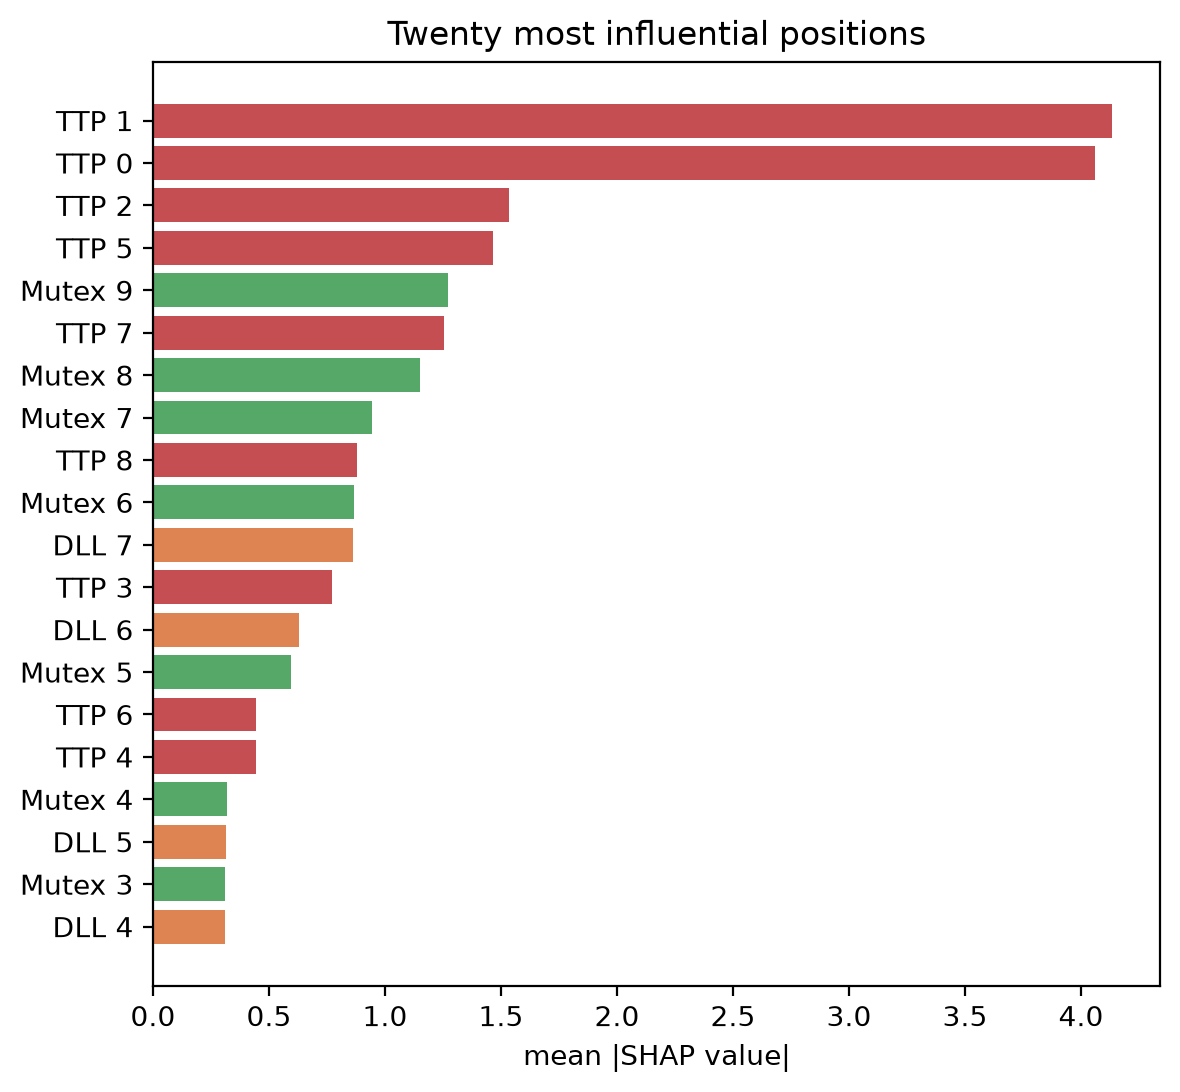

In [5]:
display(Image(str(XAI / "shap_location_importance.png"), width=850))
display(Image(str(XAI / "shap_top_positions.png"), width=480))

## 3.4 Contribution of each feature group

,group,positions,share_of_total_abs_shap,mean_abs_shap_per_position,mean_net_shap_ransomware,mean_net_shap_benign
0,ApiCall,500,0.1206,0.0068,0.4705,-0.4654
1,Dll,10,0.1289,0.3649,1.9224,-1.4994
2,Mutex,10,0.2210,0.6253,3.0027,-2.3820
3,TTP,10,0.5295,1.4983,10.8490,-8.1268


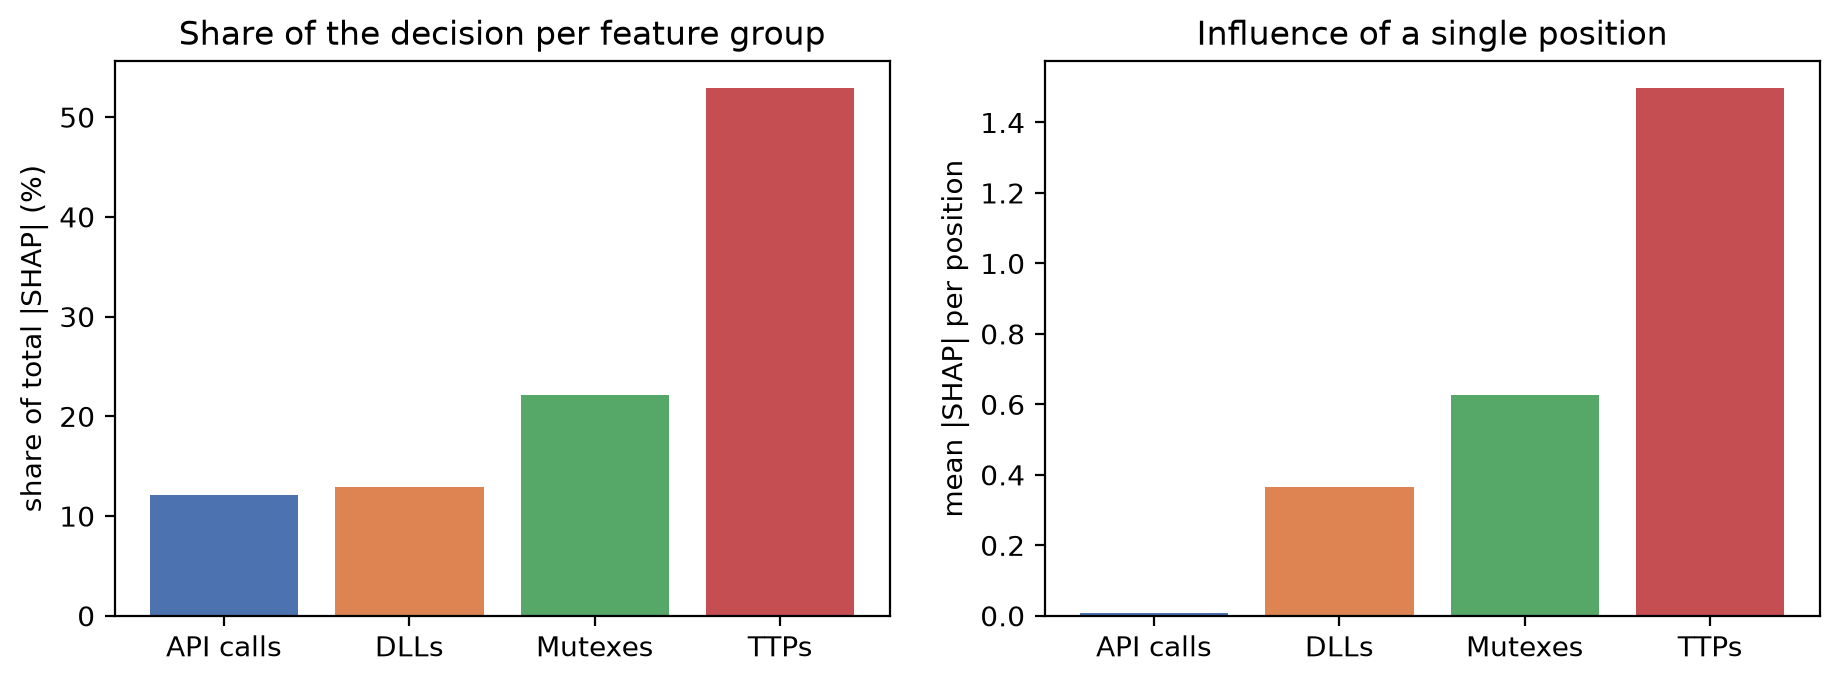

In [6]:
groups = pd.read_csv(XAI / "shap_group_contribution.csv")
display(groups.round(4))
display(Image(str(XAI / "shap_group_contribution.png"), width=800))

## 3.5 Feature-based global explanation (SHAP)

strongest ransomware indicators


,group,value,mean_shap,count
0,TTP,Unknown,11.298807,58
1,TTP,T1012,4.206346,123
2,Mutex,RasPbFile,2.014913,121
3,TTP,T1021,1.839612,115
4,TTP,T1003,1.254276,115
5,Mutex,GlobalMediaCenterMCUpdate7000000000026a1d78cdc...,1.122213,113
6,Mutex,LocalZonesLockedCacheCounterMutex,1.048177,31
7,TTP,T1098,1.010079,117
8,TTP,T1073,0.961172,115
9,Dll,sechostdll,0.905331,115


strongest benign indicators


,group,value,mean_shap,count
162,TTP,T1105,-4.275107,154
161,TTP,T1083,-3.019312,123
160,TTP,T1082,-2.783751,105
159,TTP,T1106,-2.038035,194
158,TTP,T1134,-0.946850,114
157,Dll,advapi32dll,-0.941939,85
156,Dll,apimswincoreprocessthreadsl112dll,-0.752826,22
155,Dll,apimswincorelibraryloaderl120dll,-0.481037,28
154,Mutex,GlobalCUsersAdministratorAppDataLocalMicrosoft...,-0.415787,27
153,Dll,COMCTL32dll,-0.408226,58


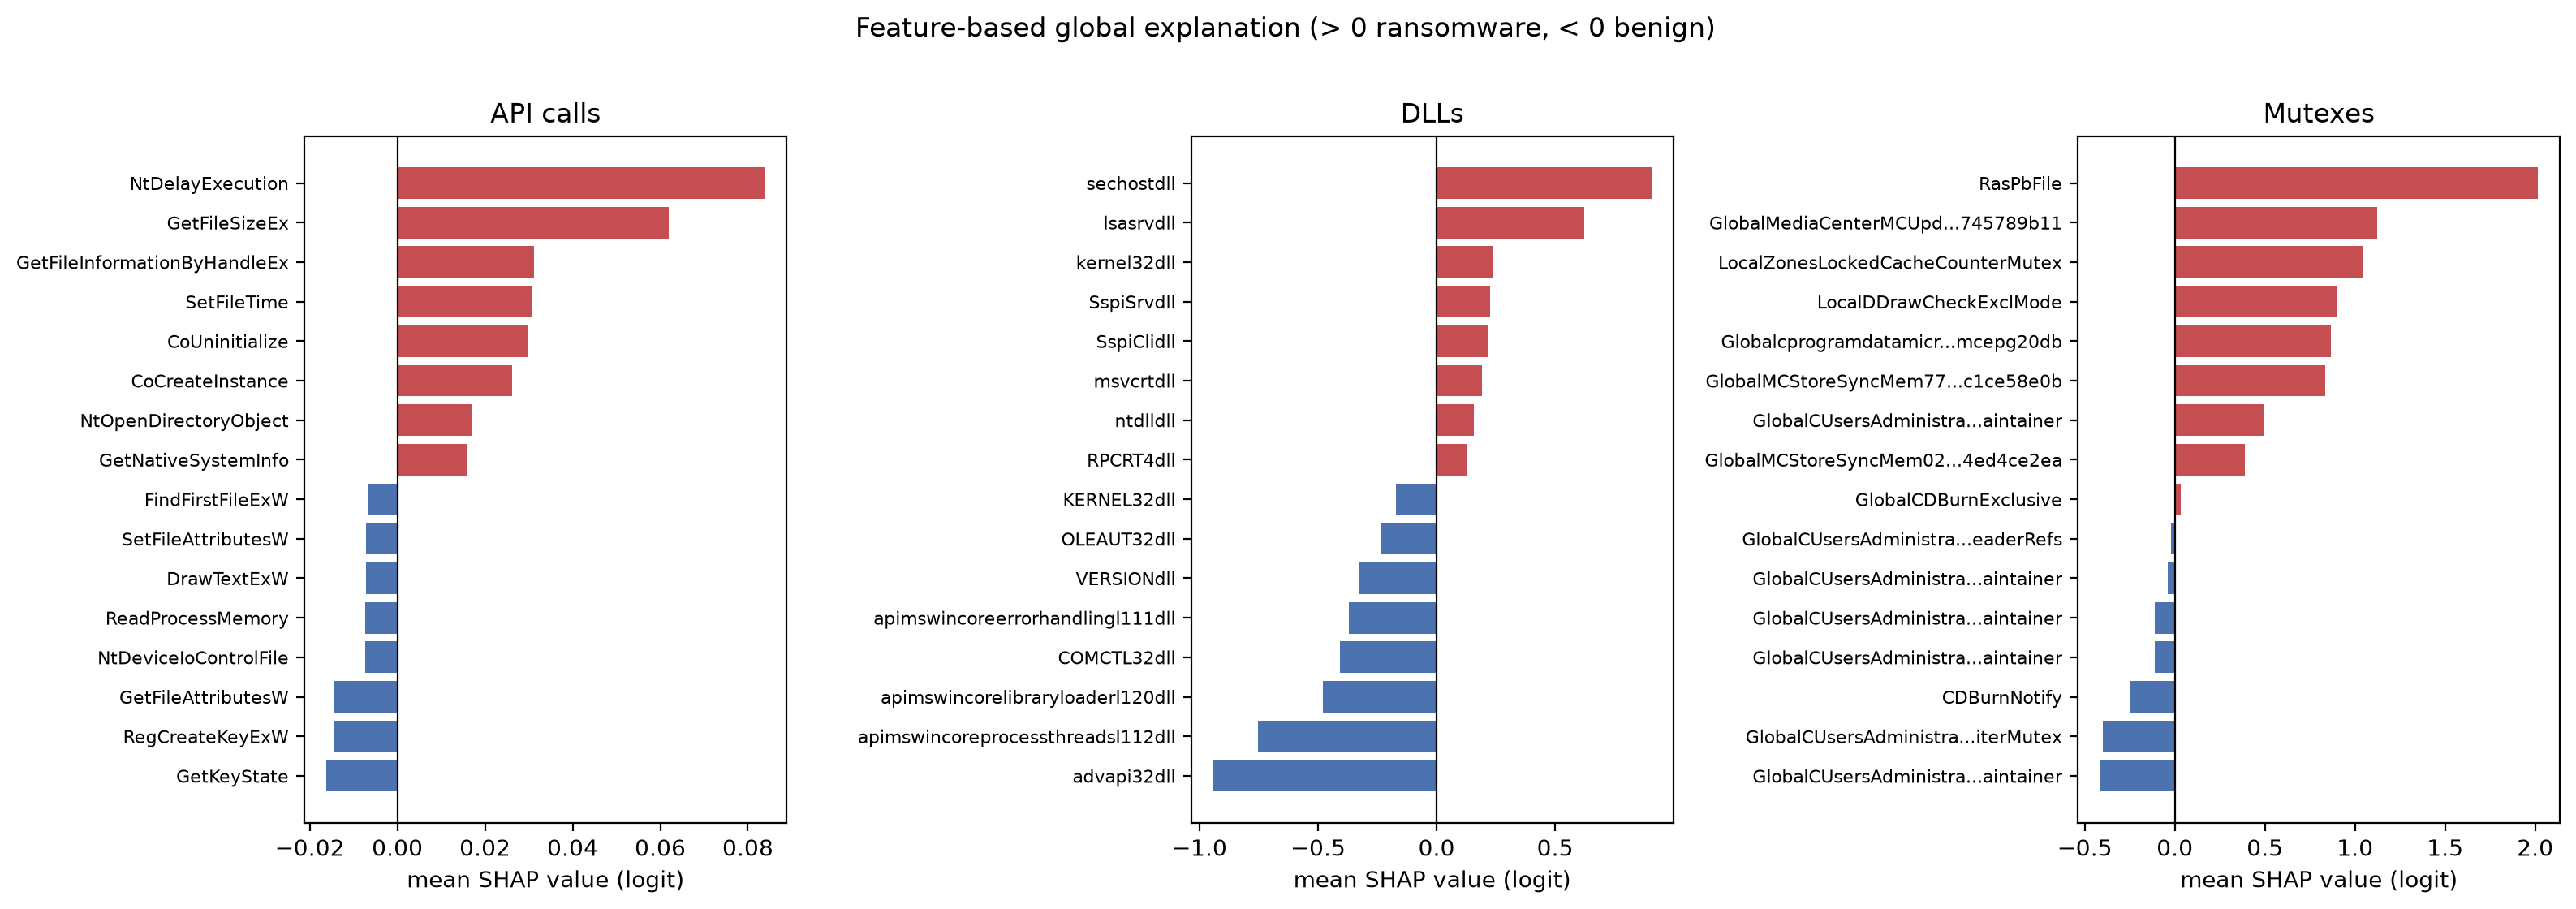

In [7]:
values = pd.read_csv(XAI / "shap_value_attributions.csv")
print("strongest ransomware indicators")
display(values.head(10))
print("strongest benign indicators")
display(values.tail(10)[::-1])
display(Image(str(XAI / "shap_value_attributions.png"), width=900))

## 3.6 ATT&CK techniques

,group,value,mean_shap,count,technique
0,TTP,Unknown,11.298807,58,Unknown
1,TTP,T1012,4.206346,123,T1012 Query Registry
2,TTP,T1021,1.839612,115,T1021 Remote Services
3,TTP,T1003,1.254276,115,T1003 OS Credential Dumping
4,TTP,T1098,1.010079,117,T1098 Account Manipulation
5,TTP,T1073,0.961172,115,T1073 DLL Side-Loading
6,TTP,T1071,0.741178,112,T1071 Application Layer Protocol
7,TTP,T1055,0.643193,123,T1055 Process Injection
8,TTP,<empty>,0.232062,2305,<empty>
9,TTP,T1027,0.026083,116,T1027 Obfuscated Files or Information


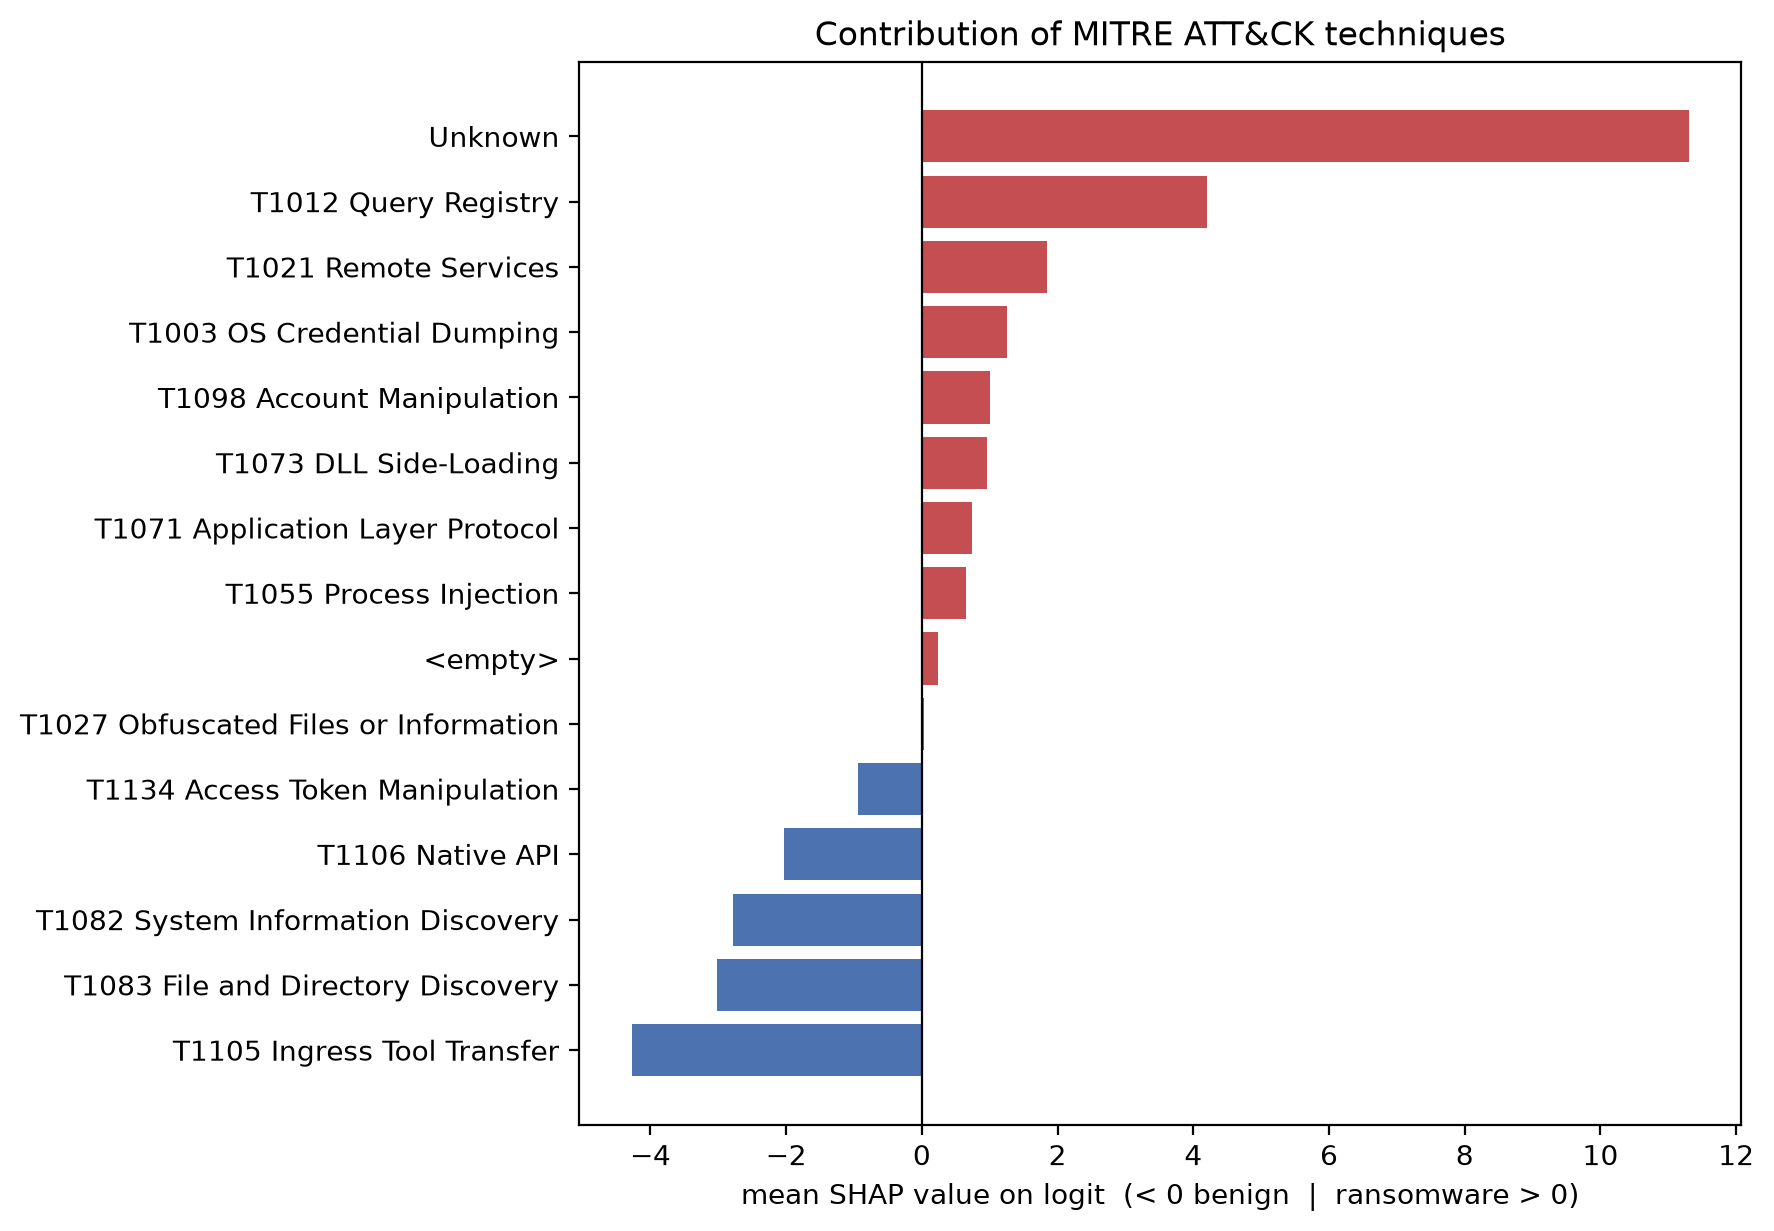

In [8]:
display(pd.read_csv(XAI / "shap_ttp_techniques.csv"))
display(Image(str(XAI / "shap_ttp_techniques.png"), width=560))